# Reconhecimento de Comandos de Voz na Borda

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gpeuzinCosta/kws-borda/blob/main/notebooks/kws_borda_relatorio.ipynb)

**Projeto final — IA025 Deep Learning (2026 S2)** · **Equipe:** Guilherme Pulizzi · Jefferson Abraham · Luciano Pinheiro
· **Repositório:** [gpeuzinCosta/kws-borda](https://github.com/gpeuzinCosta/kws-borda)

**O projeto inteiro, de ponta a ponta, em um notebook.** Reconhecer comandos curtos de voz (*keyword spotting*:
"yes", "stop", "up"...) no próprio dispositivo, com pouca memória e CPU fraca. Colocamos as famílias de redes da
disciplina (MLP, CNN 1D, ResNet, DS-CNN e Atenção), encolhidas, na mesma bancada de testes.
- **Hipótese (a):** dá para encolher essas arquiteturas e ainda reconhecer bem os comandos? (§6, §8 e §9)
- **Hipótese (b):** em redes tão pequenas, o que custa mais: o pré-processamento (MFCC) ou a rede? (§7 e §9)

Este notebook só **chama** funções das pastas do repositório (`dados/`, `modelos/`, `treino/`, `avaliacao/`,
`configs/`; ver o [README](https://github.com/gpeuzinCosta/kws-borda#readme)). Cada modelo é explorado antes no
seu playground (`notebooks/experimentos/`), onde cada passo é escrito e testado à mão.

Como usar:
1. Abra no Colab (Ambiente de execução → Alterar tipo → GPU) e rode tudo.
2. Escolha os modelos em `MODELOS` e ajuste os hiperparâmetros na seção **2. Hiperparâmetros**: tudo fica lá.
3. Partes lentas têm um flag no mesmo lugar: experimentos (§8) e datasets extras (§10). Com `RETREINAR = False`,
   o que já foi treinado é carregado do Drive.
4. Para entender um passo a fundo, siga o link para o playground de cada modelo: [CNN 1D](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb) e
   [ResNet](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_resnet_guilherme.ipynb). Lá estão também todas as configurações testadas; aqui (§8) rodam só as vencedoras.

## 1. Setup

No Colab, o Google Drive é montado e o repositório é clonado (ou atualizado). O `.tar.gz` do GSC, o cache de
MFCC e os treinos ficam em `MyDrive/kws-borda/` e sobrevivem ao fim da sessão; os áudios são extraídos no disco
local (`/content/data`), porque ler 100 mil arquivos do Drive é muito lento.

In [1]:
#@title Setup — rode esta célula primeiro
#Funciona no Colab (clona o repo e usa o Drive) e localmente/VS Code (usa a pasta do repositório).
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/gpeuzinCosta/kws-borda.git"
NO_COLAB = "google.colab" in sys.modules

if NO_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    REPO = Path("/content/kws-borda")
    if REPO.exists():
        subprocess.run(["git", "-C", str(REPO), "pull", "-q"], check=True)     #pega a versão mais nova
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO / "requirements.txt")], check=True)

    #Drive: cache de MFCC, runs e resultados PERSISTEM entre sessões
    #Disco local (/content/data): áudios extraídos, leitura rápida (o Drive é lento para 100 mil arquivos)
    os.environ["KWS_DRIVE"] = "/content/drive/MyDrive/kws-borda"
    os.environ["KWS_DATA"] = "/content/data"
else:
    #Local: sobe a partir da pasta atual até achar a raiz do repositório
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())

#A raiz do repo no sys.path deixa importar as pastas: configs, dados, modelos, treino, avaliacao
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import torch
from configs import pastas_projeto, escolher_device

PASTAS = pastas_projeto()
DOWNLOADS = Path(os.environ.get("KWS_DRIVE", REPO)) / "downloads"     #.tar.gz/.zip baixados UMA vez
device = escolher_device()
commit = subprocess.run(["git", "-C", str(REPO), "rev-parse", "--short", "HEAD"],
                        capture_output=True, text=True).stdout.strip()

print(f"Colab: {NO_COLAB} | device: {device} | commit do código: {commit}")
print(f"torch {torch.__version__} | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else '—'}")
for nome, p in PASTAS.items():
    print(f"  {nome:10s} -> {p}")

Mounted at /content/drive
Colab: True | device: cuda | commit do código: d182c01
torch 2.14.1+cu130 | GPU: Tesla T4
  dados      -> /content/data
  cache      -> /content/drive/MyDrive/kws-borda/cache
  runs       -> /content/drive/MyDrive/kws-borda/runs
  resultados -> /content/drive/MyDrive/kws-borda/runs


## 2. Hiperparâmetros

Tudo o que controla o notebook fica nesta célula:
- **Experimento:** quais modelos rodar (`MODELOS`), seeds e os flags das partes lentas. Só os modelos de
  `MODELOS` são treinados, avaliados e comparados em **todas** as seções.
- **`hyperparameters`:** o que é comum a todos os modelos (dados, MFCC, treino, avaliação). É o que deixa a
  comparação justa.
- **`hp_modelos`:** só o que muda em cada modelo: a arquitetura e, se for o caso, o próprio MFCC.

MFCC: o padrão é 40 coeficientes × 101 janelas (janela de 30 ms, passo de 10 ms). A entrada 8x menor do artigo
Hello Edge é `n_mfcc=10, janela_ms=40, passo_ms=20, center=False` (10 × 49); a CNN 1D e a ResNet usam essa.

In [ ]:
from functools import partial
from configs import montar_hp, rotulo_experimento

#Experimento
MODELOS = ["cnn1d", "resnet"]     #quais modelos treinar e rodar em TODO o notebook: "mlp", "cnn1d", "resnet", "dscnn", "atencao"
SEEDS = [0, 1, 2]          #rodadas independentes, para média ± desvio
EPOCAS = None              #None = hyperparameters['epocas']; um número sobrescreve para todos os modelos
RETREINAR = False          #False: se já existir um treino salvo no Drive para (modelo, seed), carrega em vez de treinar
RODAR_VARREDURAS = True
RODAR_RUIDO = False
RODAR_AUDIOMNIST = False
RODAR_MSWC = False

#Comum a TODOS os modelos: mesmos dados, mesmo MFCC, mesmo loop de treino e mesmas métricas
hyperparameters = {
    #Dados
    'dataset': 'speech_commands_v2',
    'tarefa': 'gsc35',          #'gsc35': as 35 palavras | 'gsc12': 10 comandos + unknown + silence
    'fracao': 1.0,              #fração do TREINO usada (1.0 = tudo). Val e teste são sempre completos
    'sample_rate': 16000,       #o GSC é gravado a 16 kHz: 1 s = 16000 amostras
    'duracao_s': 1.0,

    #MFCC (padrão: 40 coef × 101 janelas)
    'n_mfcc': 40,               #coeficientes por janela
    'janela_ms': 30,            #tamanho de cada fatia de áudio que vira uma coluna
    'passo_ms': 10,             #quanto a janela desliza
    'center': True,             #padding nas bordas, para representar o início e o fim do áudio
    'n_mels': 40,               #bandas Mel (finas nos graves, largas nos agudos, como o ouvido); n_mfcc <= n_mels
    'f_min': 20,                #abaixo de 20 Hz não é fala
    'f_max': 7600,              #um pouco antes de 8 kHz (Nyquist), onde o filtro da gravação distorce
    'normalizacao': 'global',   #'global': média/desvio por coeficiente medidos no treino | 'por_amostra': cada áudio pelas próprias estatísticas
    'spec_augment': True,       #zera faixas de tempo e de coeficientes no treino (regulariza)

    #Treino
    'epocas': 20,
    'batch_size': 128,
    'learning_rate': 0.003,
    'weight_decay': 0.01,       #penaliza pesos grandes (L2 desacoplada do AdamW)
    'otimizador': 'adamw',
    'scheduler': 'onecycle',    #aquece o lr no início e desce suavemente, passo a passo por batch
    'label_smoothing': 0.1,     #evita confiança excessiva
    'num_workers': 0,           #o MFCC já está em memória: processos extras só adicionam overhead

    #Avaliação
    'latencia_repeticoes': 300,
    'latencia_aquecimento': 30,
    'latencia_threads': 1,      #simula um dispositivo restrito (1 núcleo)
    'snrs_db': [20, 10, 5, 0, -5],
    'margem_pp': 2.0,           #critério do projeto: um modelo menor "serve" se ficar até 2 p.p. abaixo do baseline
}

#Só o que MUDA em cada modelo
hp_modelos = {
    'mlp': {'hidden': 64, 'n_camadas': 2, 'dropout': 0.1, 'batchnorm': True},

    #Vencedora da varredura (8.1): o MENOR modelo a menos de 2 p.p. do baseline 40x101 + 64 canais
    #24.275 params (23,7 KB int8), 383.280 MACs, acc val 92,46 ± 0,13% (baseline 93,51 ± 0,06%)
    'cnn1d': {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False,   #MFCC hello_edge: 10 × 49
              'canais': 48},

    #Vencedora da varredura (8.2): o MENOR modelo a menos de 2 p.p. do baseline res8 40x101
    #res15-narrow + hello_edge: 43.640 params (42,6 KB int8), 20.780.585 MACs, acc val 94,88 ± 0,09% (baseline 95,82 ± 0,03%)
    'resnet': {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False,  #MFCC hello_edge: 10 × 49
               'canais': 19, 'n_blocos': 6, 'pool': None, 'dilatacao': True, 'conv_extra': True},   #res15-narrow

    'dscnn': {'canais': 64, 'n_blocos': 4},
    'atencao': {'d_model': 64, 'n_camadas': 2, 'n_heads': 2, 'dropout': 0.1,
                'learning_rate': 0.001},     #Transformers costumam pedir lr menor
}

#config(nome, **extra): o dicionário completo do modelo `nome` (comum + o dele + extra; calcula n_classes e n_frames)
config = partial(montar_hp, hyperparameters, hp_modelos)

print("modelos:", MODELOS, "| seeds:", SEEDS)
print("experimento:", rotulo_experimento(config(MODELOS[0])))

In [3]:
#Conferência: o dicionário final de cada modelo (linhas = hiperparâmetro, colunas = modelo)
import pandas as pd

hiperparametros = {nome: config(nome, epocas=EPOCAS) for nome in MODELOS}
pd.DataFrame(hiperparametros).astype(str)

,cnn1d
dataset,speech_commands_v2
tarefa,gsc35
fracao,1.0
sample_rate,16000
duracao_s,1.0
n_mfcc,10
janela_ms,40
passo_ms,20
center,False
n_mels,40


## 3. Dados — Google Speech Commands v2

**GSC v2** (Warden, 2018): 105.835 áudios de 1 s a 16 kHz, ~2.600 pessoas, 35 palavras. O split é o **oficial,
por locutor**: quem fala no teste nunca aparece no treino.

### 3.1 Download e extração

O `.tar.gz` (2,3 GB) vai para o Drive **uma vez**; a cada sessão ele é extraído no disco local (~1–2 min).

In [4]:
import subprocess, sys

subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "gsc",
                "--destino", str(PASTAS["dados"]), "--arquivos", str(DOWNLOADS)], check=True)
RAIZ_GSC = PASTAS["dados"] / "gsc"

### 3.2 Classes e split

`gsc35`: as 35 palavras. `gsc12`: 10 comandos + `_unknown_` (outras palavras) + `_silence_` (ruído de fundo).
Cada áudio é um vetor de 16.000 números na escala [−1, 1].

{'treino': 84843, 'val': 9981, 'teste': 11005}
arquivo: backward/0165e0e8_nohash_0.wav | formato: (16000,) | palavra: backward


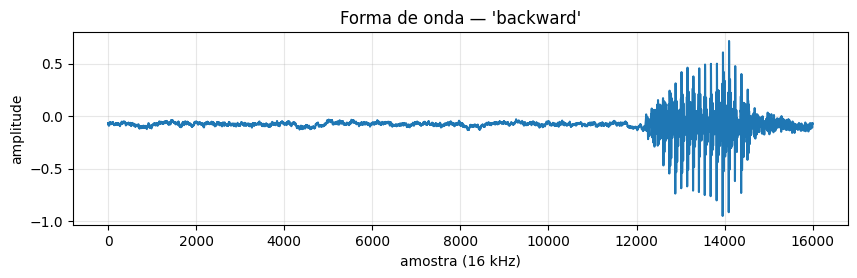

In [5]:
import matplotlib.pyplot as plt
from IPython.display import Audio
from dados import classes_da_tarefa, listar_split, ler_trecho, rotulo

CLASSES = classes_da_tarefa(hyperparameters["tarefa"])
split = listar_split(RAIZ_GSC, hyperparameters["tarefa"])
print({k: len(v) for k, v in split.items()})

exemplo = split["treino"][0]
wav = ler_trecho(RAIZ_GSC, exemplo)
print("arquivo:", exemplo, "| formato:", tuple(wav.shape), "| palavra:", exemplo.split("/")[0])

plt.figure(figsize=(10, 2.5))
plt.plot(wav.numpy()); plt.title(f"Forma de onda — '{exemplo.split('/')[0]}'")
plt.xlabel("amostra (16 kHz)"); plt.ylabel("amplitude"); plt.grid(alpha=0.3); plt.show()
Audio(wav.numpy(), rate=16000)

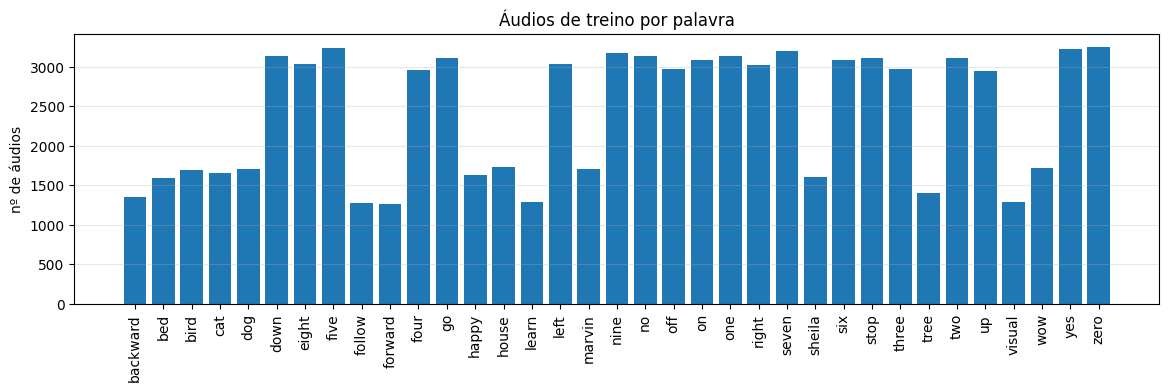

In [6]:
#Distribuição das classes no treino. Na gsc35 o GSC NÃO é balanceado (as palavras auxiliares têm menos
#exemplos); na gsc12 unknown e silence são montados com a quantidade média de um comando
import collections
contagem = collections.Counter(CLASSES[rotulo(rel, hyperparameters["tarefa"])] for rel in split["treino"])

plt.figure(figsize=(14, 3.5))
plt.bar(CLASSES, [contagem[c] for c in CLASSES])
plt.xticks(rotation=90); plt.ylabel("nº de áudios"); plt.title("Áudios de treino por palavra")
plt.grid(axis="y", alpha=0.3); plt.show()

In [7]:
from dados import locutores_em_comum

#Conferência: o split é o OFICIAL, por locutor: ninguém do treino pode aparecer na validação ou no teste
print("total:", sum(len(v) for v in split.values()), "áudios")
print("locutores em comum:", locutores_em_comum(split))      #esperado: 0 e 0

total: 105829 áudios
locutores em comum: {'treino_e_teste': 0, 'treino_e_val': 0}


### 3.3 MFCC

Cada áudio de 1 s vira uma matriz `(n_mfcc, n_frames)`: para cada janela de tempo, coeficientes que resumem o
espectro na escala Mel. O MFCC de todo o dataset é calculado **uma vez** e salvo em cache no Drive.

| MFCC | Coeficientes | Janela / passo | Entrada | Quem usa |
|---|---|---|---|---|
| padrão | 40 | 30 ms / 10 ms | 40 × 101 | MLP, DS-CNN, Atenção |
| `hello_edge` | 10 | 40 ms / 20 ms, sem padding | 10 × 49 (8x menor) | CNN 1D e ResNet (vencedoras da §8.1 e da §8.2) |

O MFCC é um `nn.Module` (`dados/mfcc.py`), então o seu tempo é medido como o de uma rede na §7.

MFCC: (10, 49) (coeficientes × janelas)


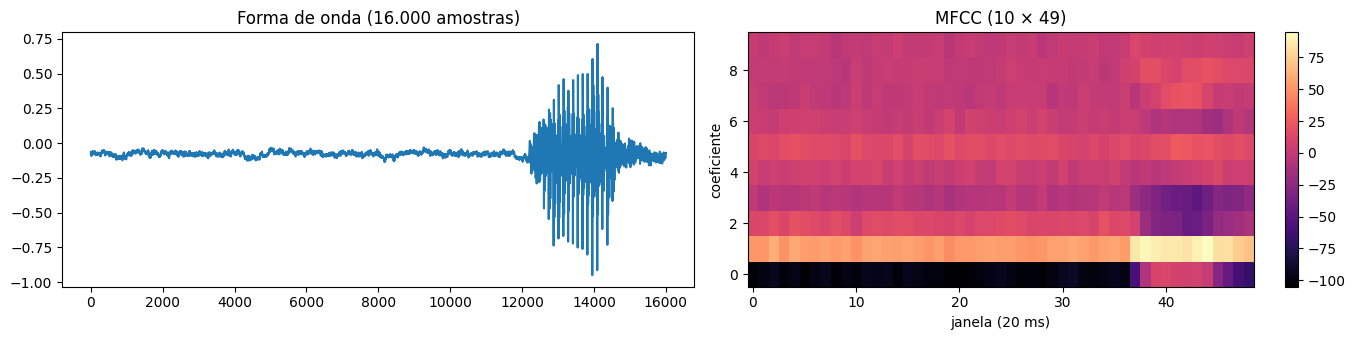

In [8]:
from dados import ExtratorMFCC

hp_base = config(MODELOS[0])      #o MFCC do primeiro modelo de MODELOS (cada modelo pode ter o seu)
extrator = ExtratorMFCC.de_hparams(hp_base)

mfcc = extrator(wav)[0]
print("MFCC:", tuple(mfcc.shape), "(coeficientes × janelas)")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].plot(wav.numpy()); axes[0].set_title("Forma de onda (16.000 amostras)")
im = axes[1].imshow(mfcc.numpy(), aspect="auto", origin="lower", cmap="magma")
axes[1].set_title(f"MFCC ({mfcc.shape[0]} × {mfcc.shape[1]})"); axes[1].set_xlabel(f"janela ({hp_base['passo_ms']} ms)"); axes[1].set_ylabel("coeficiente")
fig.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()

In [9]:
%%time
#Calcula (ou carrega do cache no Drive) o MFCC de treino/val/teste — primeira vez: ~10 min
from dados import criar_dataloaders
from treino.varredura import carregar_dados

#carregar_dados guarda UM MFCC na memória e só recarrega quando a configuração muda (cada modelo pode ter o seu)
dados = carregar_dados(hp_base, RAIZ_GSC, PASTAS["cache"])
for k, (X, y) in dados.items():
    print(f"{k:6s} | X {tuple(X.shape)} | y {tuple(y.shape)}")

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}
treino | X (84843, 10, 49) | y (84843,)
val    | X (9981, 10, 49) | y (9981,)
teste  | X (11005, 10, 49) | y (11005,)
CPU times: user 2.13 s, sys: 428 ms, total: 2.56 s
Wall time: 19.2 s


### 3.4 Normalização, SpecAugment e DataLoaders

- **Normalização global:** média e desvio por coeficiente, medidos **só no treino** (medir na val/teste seria
  vazamento).
- **SpecAugment:** zera uma faixa de janelas e uma de coeficientes, sorteadas a cada batch, só no treino. Roda no
  **batch inteiro, na GPU** (`spec_augment_batch`), e cada áudio sorteia as próprias faixas.
- **DataLoader:** entrega o batch inteiro de uma vez (uma fatia do tensor), sem montar áudio por áudio.

Cada passo é conferido em detalhe no [playground da CNN 1D](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb) (seção 3.4).

In [10]:
#Conferência: o batch que vai entrar na rede: formato e normalização (média ~0, desvio ~1)
#Com normalização por amostra, MEDIA e DESVIO são None (nada a guardar)
loaders, (MEDIA, DESVIO) = criar_dataloaders(hp_base, dados)
xb, yb = next(iter(loaders["treino"]))
print("batch:", tuple(xb.shape), "| média:", round(xb.mean().item(), 3), "| desvio:", round(xb.std().item(), 3))
print("palavras:", [CLASSES[i] for i in yb[:8].tolist()])

batch: (128, 10, 49) | média: -0.004 | desvio: 1.017
palavras: ['three', 'go', 'eight', 'nine', 'happy', 'cat', 'three', 'learn']


In [11]:
from dados import normalizar

#Conferência da normalização. Com normalização por amostra, MEDIA e DESVIO são None (cada áudio usa as próprias estatísticas)
X_treino_norm = loaders["treino"].dataset.X                 #o DatasetMFCC já guarda o MFCC normalizado
X_val_norm = normalizar(dados["val"][0], MEDIA, DESVIO)
print("treino | média dos 5 primeiros coef:", X_treino_norm.mean(dim=(0, 2))[:5])   #esperado: ~0
print("treino | desvio dos 5 primeiros coef:", X_treino_norm.std(dim=(0, 2))[:5])   #esperado: ~1
print("val    | média dos 5 primeiros coef:", X_val_norm.mean(dim=(0, 2))[:5])      #perto de 0, mas não exato
print("val    | desvio dos 5 primeiros coef:", X_val_norm.std(dim=(0, 2))[:5])      #perto de 1, mas não exato
del X_val_norm

treino | média dos 5 primeiros coef: tensor([-5.0033e-06, -5.1138e-07,  3.2912e-07, -2.4944e-08,  1.0956e-06])
treino | desvio dos 5 primeiros coef: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])
val    | média dos 5 primeiros coef: tensor([-0.0271,  0.0357, -0.0014, -0.0108,  0.0164])
val    | desvio dos 5 primeiros coef: tensor([1.0047, 1.0018, 1.0106, 1.0181, 0.9997])


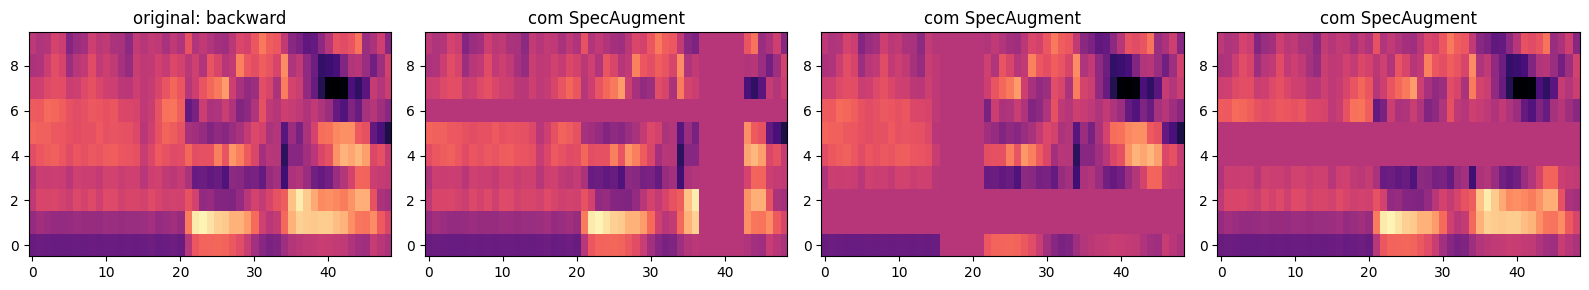

fração de zeros | batch com aumento: 0.183 | sem aumento: 0.0


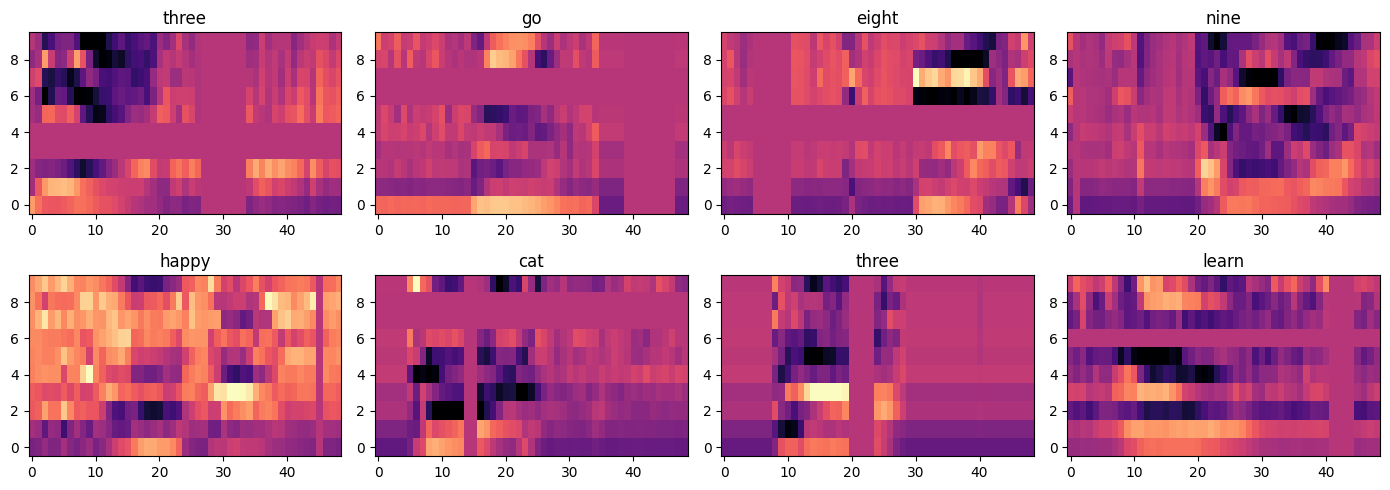

In [12]:
from dados import spec_augment_batch
from avaliacao.graficos import plot_spec_augment, plot_batch

#Um áudio da validação: o original e 3 sorteios do SpecAugment
plot_spec_augment(loaders["val"].dataset.X[0], CLASSES[loaders["val"].dataset.y[0]])

#No treino, o aumento no batch inteiro, como o treinar_uma_epoca faz
xb_aum = spec_augment_batch(xb.to(device)).cpu()
print("fração de zeros | batch com aumento:", round((xb_aum == 0).float().mean().item(), 3),
      "| sem aumento:", round((xb == 0).float().mean().item(), 3))      #esperado: ~0.13 e 0
plot_batch(xb_aum, yb, CLASSES)

## 4. Modelos

As 5 famílias da disciplina, em versões **pequenas**, uma por arquivo em `modelos/`. A tabela abaixo vem do
registro de modelos: um modelo novo aparece sozinho.

| Família | Ideia | Arquivo | Situação |
|---|---|---|---|
| MLP | achata o MFCC e passa por camadas densas; sem noção de tempo. É o *baseline* | `modelos/mlp.py` | pronto |
| CNN 1D | os coeficientes viram canais e a convolução desliza no tempo: 4 blocos Conv1d k=3 + BN + ReLU, média global, `head` | `modelos/cnn1d.py` | pronto: `hello_edge` + 48 canais, vencedora da §8.1 ([playground](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb)) |
| ResNet | Conv2d com atalhos residuais `x + F(x)` (famílias res8/res15/res26, Tang & Lin 2018) | `modelos/resnet.py` | pronto: res15-narrow + `hello_edge`, vencedora da §8.2 ([playground](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_resnet_guilherme.ipynb)) |
| DS-CNN | convolução separável em profundidade (Hello Edge): ~8–9x menos parâmetros | `modelos/dscnn.py` | a fazer |
| Atenção (KWT) | cada janela do MFCC vira um token; autoatenção + token `[CLS]` | `modelos/atencao.py` | a fazer |

In [13]:
import pandas as pd
from modelos import listar_modelos

pd.DataFrame(listar_modelos())

,nome,familia,referencia,implementado
0,mlp,MLP,Bengio et al. 2003 (exercício da disciplina),True
1,cnn1d,CNN 1D,Choi et al. 2019 (TC-ResNet) / exercício de CNNs,True
2,resnet,ResNet,He et al. 2016; Tang & Lin 2018 (res8),False
3,dscnn,DS-CNN,Zhang et al. 2017 — Hello Edge (arXiv:1711.07128),False
4,atencao,Atenção,Vaswani et al. 2017; Berg et al. 2021 — KWT (a...,False


### 4.1 Contrato e custo

**Contrato**:
- entrada `x`: `(B, n_mfcc, n_frames)`, o MFCC normalizado (cada modelo com o seu);
- saída: logits `(B, n_classes)`;
- a última camada se chama `self.head`;
- o `__init__` recebe `n_classes, n_mfcc, n_frames` e, depois, os hiperparâmetros da arquitetura (`hp_modelos`).

**Custo** (depende só da arquitetura, então dá para medir antes de treinar):
- **Parâmetros:** tamanho em memória = parâmetros × 4 bytes (fp32) ou × 1 byte (int8).
- **MACs:** multiplicações + somas para classificar **um** áudio (1 MAC = 2 FLOPs).

In [14]:
from avaliacao import custo
from modelos import criar_modelo, esta_implementado

linhas = []
for nome in MODELOS:
    if not esta_implementado(nome):
        print(f"[pulando] {nome}: ainda não implementado")
        continue
    hp = config(nome)
    linhas.append(dict(modelo=nome, entrada=f"{hp['n_mfcc']}x{hp['n_frames']}", **custo(criar_modelo(nome, hp))))

tabela_custo = pd.DataFrame(linhas)
tabela_custo.style.format({"params": "{:,}", "kb_fp32": "{:.0f}", "kb_int8": "{:.0f}", "macs": "{:,}"})

,modelo,entrada,params,kb_fp32,kb_int8,macs
0,cnn1d,10x49,"24,275",95,24,"383,280"


In [15]:
#Conferência do contrato de cada modelo com a SUA entrada (o MFCC do seu config):
#(B, n_mfcc, n_frames) -> (B, n_classes), com a última camada chamada `head`
for nome in MODELOS:
    if not esta_implementado(nome):
        continue
    hp = config(nome)
    modelo = criar_modelo(nome, hp).eval()
    saida = modelo(torch.randn(4, hp["n_mfcc"], hp["n_frames"]))
    print(f"{nome:8s} | entrada (4, {hp['n_mfcc']}, {hp['n_frames']}) -> saída {tuple(saida.shape)} | "
          f"tem head: {hasattr(modelo, 'head')}")      #esperado: (4, n_classes) e True

cnn1d    | entrada (4, 10, 49) -> saída (4, 35) | tem head: True


## 5. Treino

**O mesmo loop para todas as redes** (`treino/loop.py`), com os valores de `hyperparameters`:

| Item | Valor |
|---|---|
| Otimizador | AdamW, lr 3e-3, weight decay 1e-2 |
| Agendador | OneCycle, passo a passo por batch |
| Perda | entropia cruzada com *label smoothing* 0,1 |
| Aumento | SpecAugment no batch inteiro, na GPU |
| Seleção | pesos da **melhor época na validação** |
| Repetições | `SEEDS` (média ± desvio) |

Cada treino fica salvo no Drive (`runs/`). As funções de época vieram do [playground da CNN 1D](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb) (seção 5).

In [16]:
from treino import treinar, carregar_run
from treino.varredura import carregar_dados
from dados import ExtratorMFCC
from avaliacao.graficos import curvas_treino

treinados = {}   #{nome: [(seed, model, hist), ...]}
entradas = {}    #{nome: dict(extrator, media, desvio)}: a entrada de cada modelo (o MFCC pode mudar por modelo)

for nome in MODELOS:
    if not esta_implementado(nome):
        print(f"[pulando] {nome}: ainda não implementado")
        continue
    hp = config(nome, epocas=EPOCAS)
    #MFCC e batch_size do próprio modelo (hp_modelos, §2)
    loaders_m, (media, desvio) = criar_dataloaders(hp, carregar_dados(hp, RAIZ_GSC, PASTAS["cache"]))
    entradas[nome] = dict(extrator=ExtratorMFCC.de_hparams(hp), media=media, desvio=desvio)
    treinados[nome] = []
    for seed in SEEDS:
        print(f"\n===== {nome} | seed {seed} =====")
        run = None if RETREINAR else carregar_run(PASTAS["runs"], hp, seed)
        model = criar_modelo(nome, hp)
        if run is not None:
            model.load_state_dict(run[0]); hist = run[1]
            print(f"carregado do Drive: {hist.get('pasta')} | melhor acc val {max(hist['acc'])*100:.2f}%")
        else:
            model, hist = treinar(model, loaders_m, hp, seed=seed, pasta_runs=PASTAS["runs"], device=device)
        treinados[nome].append((seed, model.to(device), hist))


===== cnn1d | seed 0 =====
carregado do Drive: /content/drive/MyDrive/kws-borda/runs/cnn1d_gsc35_10x49_global_s0_20261107-170157 | melhor acc val 92.66%

===== cnn1d | seed 1 =====
carregado do Drive: /content/drive/MyDrive/kws-borda/runs/cnn1d_gsc35_10x49_global_s1_20261107-170257 | melhor acc val 92.88%

===== cnn1d | seed 2 =====
carregado do Drive: /content/drive/MyDrive/kws-borda/runs/cnn1d_gsc35_10x49_global_s2_20261107-170356 | melhor acc val 92.60%


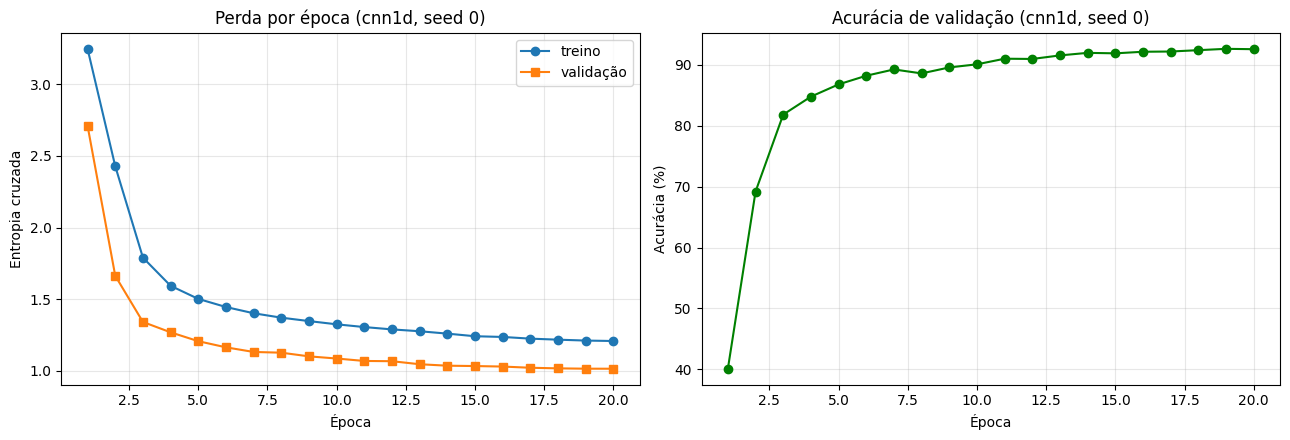

In [17]:
#Curvas de treino da primeira seed de cada modelo
for nome, rodadas in treinados.items():
    curvas_treino(rodadas[0][2], titulo=f"({nome}, seed {rodadas[0][0]})")

In [18]:
#Resumo do treino: uma linha por (modelo, seed). Gap = perda de validação - perda de treino na última época
pd.DataFrame([dict(modelo=nome, seed=seed,
                   melhor_acc_val=hist.get("melhor_acc", max(hist["acc"])),
                   melhor_epoca=hist.get("melhor_epoca"), acc_final=hist.get("acc_final", hist["acc"][-1]),
                   gap=hist.get("gap"), tempo_min=hist.get("tempo_min"))
              for nome, rodadas in treinados.items() for seed, model, hist in rodadas]).round(4)

,modelo,seed,melhor_acc_val,melhor_epoca,acc_final,gap,tempo_min
0,cnn1d,0,0.9266,19,0.9260,-0.1932,1.0237
1,cnn1d,1,0.9288,18,0.9286,-0.1914,0.9946
2,cnn1d,2,0.9260,17,0.9250,-0.1935,0.9912


## 6. Avaliação no teste

Teste = 11.005 áudios de locutores nunca vistos, média ± desvio entre as seeds.
- **Acurácia:** fração de acertos.
- **F1 macro:** média do F1 de cada classe; pesa todas as palavras igualmente.
- **Matriz de confusão:** linha = palavra verdadeira, coluna = prevista (normalizada por linha). Esperamos erros
  **fonéticos** (*tree* ↔ *three*, *go* ↔ *no*).

Cada rodada também é registrada em `runs/resultados.csv` no Drive.

In [19]:
from treino import prever
from avaliacao import acuracia, f1_macro, registrar
from avaliacao.resultados import consolidar
from treino.varredura import carregar_dados

linhas, predicoes = [], {}
for nome, rodadas in treinados.items():
    hp = config(nome)
    loaders_m, _ = criar_dataloaders(hp, carregar_dados(hp, RAIZ_GSC, PASTAS["cache"]))
    for seed, model, hist in rodadas:
        y_pred, y_true = prever(model, loaders_m["teste"])
        predicoes[(nome, seed)] = (y_pred, y_true)
        r = dict(acc=acuracia(y_pred, y_true), f1=f1_macro(y_pred, y_true))
        registrar(PASTAS["resultados"] / "resultados.csv", nome, seed, experimento=rotulo_experimento(hp),
                  commit=commit, **r)
        linhas.append(dict(modelo=nome, seed=seed, dataset="gsc_v2", **r))

resultados_gsc = consolidar(pd.DataFrame(linhas))
if len(resultados_gsc):
    resultados_gsc = resultados_gsc.merge(tabela_custo, on="modelo")
resultados_gsc

>>> registrado: cnn1d (seed 0, gsc_v2) | experimento=gsc35_10x49_global | commit=d182c01 | acc=0.9139 | f1=0.9070
>>> registrado: cnn1d (seed 1, gsc_v2) | experimento=gsc35_10x49_global | commit=d182c01 | acc=0.9145 | f1=0.9080
>>> registrado: cnn1d (seed 2, gsc_v2) | experimento=gsc35_10x49_global | commit=d182c01 | acc=0.9122 | f1=0.9038


,modelo,dataset,acc_mean,acc_std,acc_count,f1_mean,f1_std,f1_count,entrada,params,kb_fp32,kb_int8,macs
0,cnn1d,gsc_v2,0.913554,0.001186,3,0.906265,0.002187,3,10x49,24275,94.824219,23.706055,383280


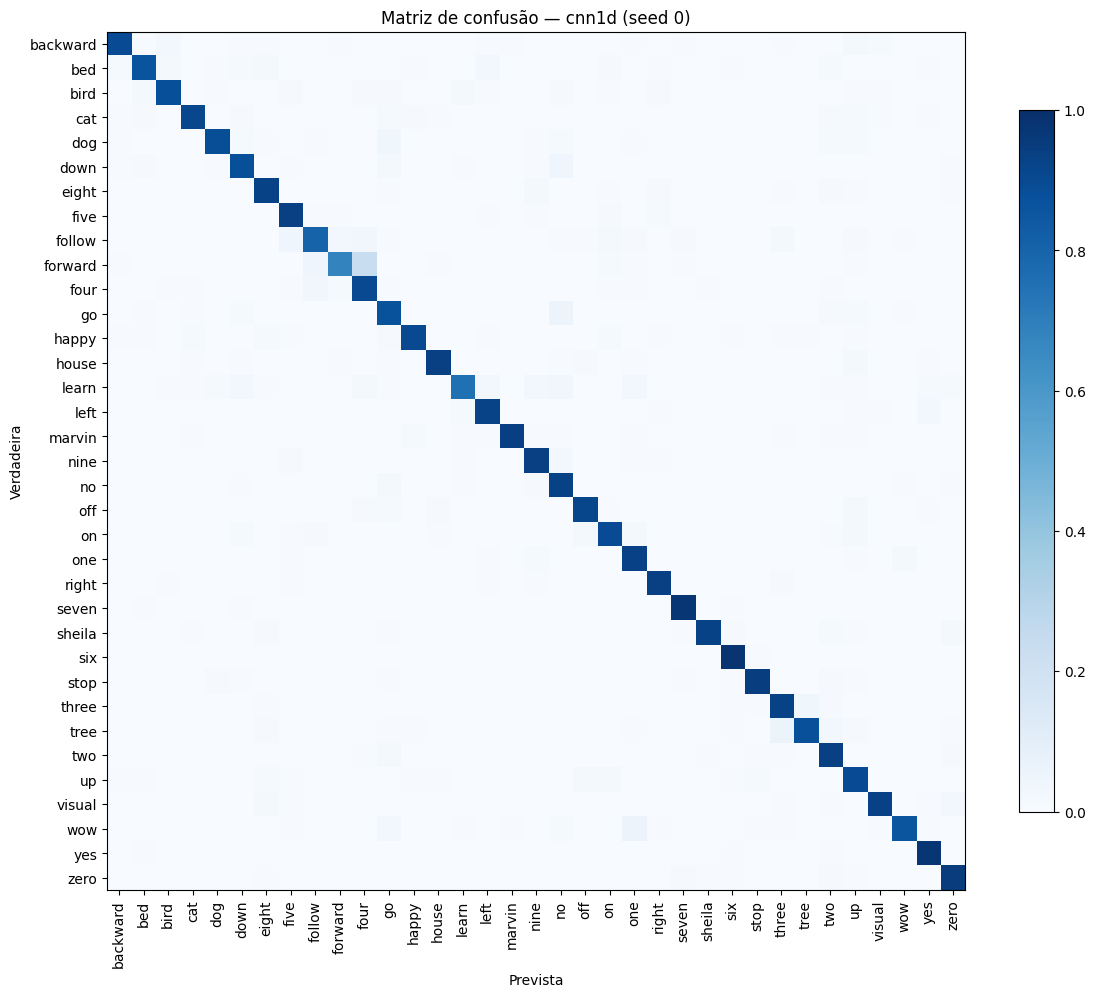

,verdadeira,prevista,fração
0,forward,four,0.232258
1,wow,one,0.058252
2,go,no,0.054726
3,tree,three,0.051813
4,down,no,0.046798
5,forward,follow,0.045161
6,follow,five,0.040698
7,learn,no,0.037267
8,three,tree,0.037037
9,dog,go,0.036364


,precisao,revocacao,f1,exemplos
forward,0.854,0.677,0.755,155
learn,0.864,0.752,0.804,161
follow,0.821,0.802,0.812,172
go,0.837,0.871,0.854,402
bed,0.873,0.860,0.866,207
up,0.865,0.892,0.878,425
four,0.863,0.900,0.881,400
no,0.841,0.926,0.881,405
wow,0.912,0.859,0.885,206
tree,0.909,0.876,0.892,193


In [20]:
from avaliacao import matriz_confusao, relatorio_por_classe, top_confusoes
from avaliacao.graficos import plot_matriz_confusao

if len(resultados_gsc):
    melhor = resultados_gsc.sort_values("acc_mean", ascending=False).iloc[0]["modelo"]
    y_pred, y_true = predicoes[(melhor, SEEDS[0])]
    cm = matriz_confusao(y_pred, y_true, n_classes=len(CLASSES))
    plot_matriz_confusao(cm, CLASSES, titulo=f"Matriz de confusão — {melhor} (seed {SEEDS[0]})")
    display(pd.DataFrame(top_confusoes(cm, CLASSES, k=10), columns=["verdadeira", "prevista", "fração"]))

    #Precisão, revocação e F1 de cada palavra do melhor modelo, da pior para a melhor
    display(relatorio_por_classe(y_pred, y_true, CLASSES).round(3))

In [21]:
#Ranking de F1 por classe no TESTE (seed SEEDS[0]): uma coluna por modelo, das palavras mais difíceis para as mais fáceis
if len(resultados_gsc):
    ranking = pd.DataFrame({nome: relatorio_por_classe(*predicoes[(nome, SEEDS[0])], CLASSES)["f1"]
                            for nome in treinados})
    display(ranking.sort_values(list(ranking.columns)[0]).round(3))

,cnn1d
forward,0.755
learn,0.804
follow,0.812
go,0.854
bed,0.866
up,0.878
four,0.881
no,0.881
wow,0.885
tree,0.892


## 7. Latência (MFCC × rede) — hipótese (b)

Protocolo: CPU com **1 thread**, **batch 1** (um comando por vez, como no dispositivo), aquecimento e mediana de
300 repetições. **MFCC, normalização e rede são medidos separados**, em rodadas: se a razão (pré-processamento /
rede) oscilar mais de 30%, a medida é refeita. O MFCC também é medido com o librosa, para ver se a biblioteca muda
a resposta. Cada escolha é explicada no [playground da CNN 1D](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb) (seção 7).

,modelo,entrada,mfcc_ms,mfcc_p95_ms,norm_ms,norm_p95_ms,rede_ms,rede_p95_ms,preproc_ms,preproc_sobre_rede,...,razao_max,oscilacao,estavel,tentativas_feitas,rede_x8_ms,fator_x8,rodadas,cpu,mfcc_librosa_ms,mfcc_librosa_p95_ms
0,cnn1d,10x49,0.66,0.827,0.009,0.01,0.512,0.581,0.669,1.353,...,1.428,0.218,True,1,1.405,2.745,5,Intel(R) Xeon(R) CPU @ 2.00GHz,1.926,2.273


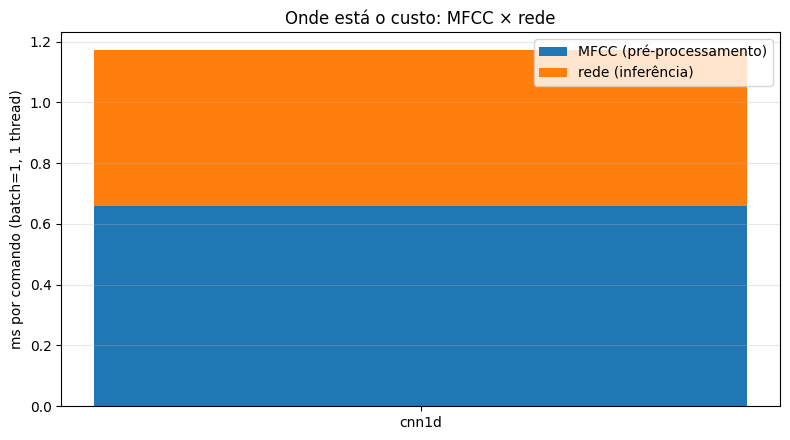

In [22]:
from avaliacao import medir_latencia
from avaliacao.graficos import barras_latencia

linhas = []
for nome in MODELOS:
    if not esta_implementado(nome):
        continue
    hp = config(nome)
    if nome in treinados:
        model, media, desvio = treinados[nome][0][1], entradas[nome]["media"], entradas[nome]["desvio"]
    elif hp["normalizacao"] == "global":
        #Sem treino: média 0 e desvio 1 têm o mesmo custo (o tempo depende só do formato)
        model, media, desvio = criar_modelo(nome, hp), torch.zeros(hp["n_mfcc"], 1), torch.ones(hp["n_mfcc"], 1)
    else:
        model, media, desvio = criar_modelo(nome, hp), None, None
    linhas.append(dict(modelo=nome, entrada=f"{hp['n_mfcc']}x{hp['n_frames']}",
                       **medir_latencia(model, hp, media, desvio, com_librosa=True)))

latencia = pd.DataFrame(linhas)
if len(latencia):
    display(latencia.round(3))
    barras_latencia(latencia)

## 8. Experimentos

Cada família foi explorada antes no seu playground, com uma varredura de configurações: quanto dá para encolher o
modelo sem perder reconhecimento? **Aqui rodam só duas configurações por família**: o *baseline* (a referência do
critério) e o **vencedor**. As tabelas "O que encontramos" trazem os números das outras configurações, e a execução
completa, com as saídas salvas, está no playground de cada modelo. O código é o mesmo para todos
(`treino/varredura.py`): muda só a lista de configurações. Com `RETREINAR = False`, os treinos do playground salvos
no Drive são reaproveitados.

**Critério, definido antes de ver os resultados:** o vencedor é o **menor** modelo (parâmetros, depois MACs) até
**2 p.p.** abaixo do baseline na acurácia de **validação**. O teste só é reportado. A latência segue a §7, em 3
passadas, ficando com a mais rápida.

### 8.1 CNN 1D: quanto dá para encolher

No [playground da CNN 1D](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb) (seções 8 e 9) foram 13 configurações (`CONFIGS_CNN1D`) × 3 seeds, no GSC
completo e com o loop da §5:

| Grupo | Configurações |
|---|---|
| baseline | entrada 40 × 101, 64 canais |
| treino | sem SpecAugment, normalização por amostra, sem weight decay |
| largura | 32, 16, 8 e 4 canais |
| entrada `hello_edge` (10 × 49) | 64, 48, 32, 16 e 8 canais |

Aqui rodam o **baseline** e o **vencedor** (`hello_edge` + 48 canais).

In [ ]:
from treino.varredura import (CONFIGS_CNN1D, rodar_varredura, medir_latencias_varredura, anexar_latencias,
                              montar_resumo, tabela_slide, escolher_vencedor, matrizes_escolhidos)

#Só o baseline (referência do critério) e o vencedor. As 13 configurações estão no playground da CNN 1D
CONFIGS_CNN1D_RELATORIO = [c for c in CONFIGS_CNN1D if c[0] in ('baseline', 'hello_edge + canais 48')]

hp_cnn1d = config("cnn1d", epocas=EPOCAS)
VARRER_CNN1D = RODAR_VARREDURAS and "cnn1d" in MODELOS

if VARRER_CNN1D:
    tabela_cnn1d, modelos_cnn1d = rodar_varredura("cnn1d", CONFIGS_CNN1D_RELATORIO, hp_cnn1d, SEEDS, RAIZ_GSC, PASTAS,
                                                  retreinar=RETREINAR, device=device)
else:
    print("[pulando] §8.1: RODAR_VARREDURAS=False ou cnn1d fora de MODELOS")

In [ ]:
#Latência de cada configuração (CPU, 1 thread, batch 1) e o resumo por configuração (média ± desvio entre as seeds)
if VARRER_CNN1D:
    latencias_cnn1d = medir_latencias_varredura("cnn1d", CONFIGS_CNN1D_RELATORIO, hp_cnn1d)
    tabela_cnn1d = anexar_latencias(tabela_cnn1d, latencias_cnn1d)
    resumo_cnn1d = montar_resumo(tabela_cnn1d, hp_cnn1d["fracao"], hp_cnn1d["margem_pp"])

    #Todos os treinos, um por linha
    display(tabela_cnn1d[["experimento", "seed", "entrada", "canais", "params", "macs", "acc_val", "melhor_epoca",
                          "gap", "acc_teste", "f1_teste", "mfcc_ms", "rede_ms", "tempo_min"]].round(4))

In [ ]:
from avaliacao.graficos import acuracia_vs_custo_varredura, barras_preproc_rede

if VARRER_CNN1D:
    #A tabela dos slides
    display(tabela_slide(resumo_cnn1d))

    #Acurácia × custo, com o piso do critério de 2 p.p.
    acuracia_vs_custo_varredura(resumo_cnn1d, hp_cnn1d["margem_pp"])

    #Hipótese (b) dentro da varredura: pré-processamento × rede
    barras_preproc_rede(resumo_cnn1d)

In [ ]:
if VARRER_CNN1D:
    vencedor_cnn1d = escolher_vencedor(resumo_cnn1d)

    #Conferência: hp_modelos['cnn1d'] (§2, usado no resto do notebook) precisa ser exatamente o vencedor
    mudancas_vencedor = dict(CONFIGS_CNN1D_RELATORIO)[vencedor_cnn1d]
    hp_vencedor = config("cnn1d")
    print("hp_modelos['cnn1d'] usa o vencedor:", all(hp_vencedor[k] == v for k, v in mudancas_vencedor.items()),
          {k: hp_vencedor[k] for k in mudancas_vencedor})

In [ ]:
#Matrizes de confusão (no TESTE, somadas entre as seeds) de 3 configurações escolhidas pela VALIDAÇÃO:
#o baseline e o vencedor (o que ficou logo abaixo da linha dos 2 p.p. está no playground)
if VARRER_CNN1D:
    matrizes_escolhidos(resumo_cnn1d, modelos_cnn1d, CONFIGS_CNN1D_RELATORIO, hp_cnn1d, SEEDS, RAIZ_GSC, PASTAS["cache"])

#### O que encontramos

Execução do [playground da CNN 1D](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb) (com as saídas salvas): GSC completo, 20 épocas, 3 seeds, latência numa CPU Intel Xeon
2,0 GHz do Colab.
Quando este notebook roda, as tabelas acima, geradas pela própria seção, são a fonte para o baseline e o vencedor;
as demais linhas vêm do playground.

| Configuração | Entrada | Params | MACs | Acc val (%) | Acc teste (%) | MFCC / rede (ms) |
|---|---|---|---|---|---|---|
| baseline | 40 × 101 | 47.331 | 1.883.840 | 93,51 ± 0,06 | 92,58 ± 0,25 | 0,68 / 0,45 |
| entrada hello_edge (64 canais) | 10 × 49 | 41.571 | 649.280 | 93,46 ± 0,04 | 92,59 ± 0,29 | 0,50 / 0,35 |
| **hello_edge + 48 canais (vencedor)** | 10 × 49 | **24.275** | **383.280** | **92,46 ± 0,13** | **91,45 ± 0,26** | 0,48 / 0,34 |
| canais 32 | 40 × 101 | 14.467 | 665.440 | 90,62 ± 0,16 | 89,12 ± 0,24 | 0,69 / 0,36 |
| hello_edge + 32 canais | 10 × 49 | 11.587 | 186.400 | 90,20 ± 0,09 | 88,90 ± 0,34 | 0,50 / 0,32 |
| canais 16 | 40 × 101 | 4.947 | 263.600 | 84,16 ± 0,86 | 82,40 ± 0,61 | 0,68 / 0,31 |
| canais 4 | 40 × 101 | 831 | 52.940 | 40,38 ± 2,77 | 39,08 ± 2,32 | 0,68 / 0,29 |

- **A entrada menor sai de graça:** com 64 canais, trocar 40 × 101 por 10 × 49 não perde nada na validação
  (93,46% contra 93,51%), corta os MACs em ~3× e o MFCC em ~27% (0,68 → 0,50 ms).
- **A largura é o que pesa:** abaixo de 48 canais a acurácia cai rápido (32 canais: −2,9 p.p.; 16: −9,4 p.p.;
  4: −53 p.p.).
- **Vencedor:** `hello_edge` + 48 canais, com **metade dos parâmetros** e **1/5 dos MACs** do baseline, a
  −1,05 p.p. na validação. É a configuração de `hp_modelos['cnn1d']` (§2), usada no resto do notebook.
- **Treino:** o SpecAugment ajuda (+0,38 p.p.) e o weight decay quase não muda (+0,07 p.p.). A normalização por
  amostra foi a **melhor** configuração (+0,35 p.p. sobre o baseline); combiná-la com o vencedor é um próximo passo.
- **Hipótese (b), já aqui:** em todas as configurações o pré-processamento (MFCC + normalização) custa **mais**
  que a rede: 1,45× no vencedor e até 2,4× nos modelos menores. Encolher só a rede não resolve, porque o MFCC
  passa a dominar.

### 8.2 ResNet: quanto dá para encolher

Conv2d 3 × 3 sobre o MFCC tratado como uma imagem de 1 canal, com atalhos residuais `x + F(x)`. As famílias vêm do
Tang & Lin (2018); as versões *narrow* usam 19 canais em vez de 45:

| Família | Blocos | Pooling na entrada | Detalhe |
|---|---|---|---|
| res8 | 3 | média 3 × 4 | a mais rasa e barata |
| res15 | 6 | nenhum | convoluções dilatadas (1, 1, 2, 2, 2, 4...) + 1 conv extra |
| res26 | 12 | média 2 × 2 | a mais profunda |

No [playground da ResNet](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_resnet_guilherme.ipynb) (seção 7) foram 15 configurações (`CONFIGS_RESNET`) × 3 seeds, no GSC completo
e com o loop da §5:

| Grupo | Configurações |
|---|---|
| baseline | res8, entrada 40 × 101 |
| treino | sem SpecAugment, normalização por amostra, sem weight decay |
| menores que o res8 | res8-narrow, res15-narrow, res26-narrow, res8 com 12 e com 8 canais |
| entrada `hello_edge` (10 × 49) | res8 e todas as menores acima |

Aqui rodam o **baseline** e o **vencedor** (res15-narrow + `hello_edge`).

In [ ]:
from treino.varredura import CONFIGS_RESNET

#Só o baseline (referência do critério) e o vencedor. As 15 configurações estão no playground da ResNet
CONFIGS_RESNET_RELATORIO = [c for c in CONFIGS_RESNET if c[0] in ('baseline', 'res15-narrow + hello_edge')]

hp_resnet = config("resnet", epocas=EPOCAS)
VARRER_RESNET = RODAR_VARREDURAS and "resnet" in MODELOS

if VARRER_RESNET:
    tabela_resnet, modelos_resnet = rodar_varredura("resnet", CONFIGS_RESNET_RELATORIO, hp_resnet, SEEDS, RAIZ_GSC,
                                                    PASTAS, retreinar=RETREINAR, device=device)
else:
    print("[pulando] §8.2: RODAR_VARREDURAS=False ou resnet fora de MODELOS")

In [ ]:
#Latência de cada configuração (CPU, 1 thread, batch 1) e o resumo por configuração (média ± desvio entre as seeds)
if VARRER_RESNET:
    latencias_resnet = medir_latencias_varredura("resnet", CONFIGS_RESNET_RELATORIO, hp_resnet)
    tabela_resnet = anexar_latencias(tabela_resnet, latencias_resnet)
    resumo_resnet = montar_resumo(tabela_resnet, hp_resnet["fracao"], hp_resnet["margem_pp"])

    #Todos os treinos, um por linha
    display(tabela_resnet[["experimento", "seed", "entrada", "canais", "n_blocos", "params", "macs", "acc_val",
                           "melhor_epoca", "gap", "acc_teste", "f1_teste", "mfcc_ms", "rede_ms", "tempo_min"]].round(4))

In [ ]:
if VARRER_RESNET:
    #A tabela dos slides
    display(tabela_slide(resumo_resnet))

    #Acurácia × custo, com o piso do critério de 2 p.p.
    acuracia_vs_custo_varredura(resumo_resnet, hp_resnet["margem_pp"])

    #Hipótese (b) dentro da varredura: pré-processamento × rede
    barras_preproc_rede(resumo_resnet)

In [ ]:
if VARRER_RESNET:
    vencedor_resnet = escolher_vencedor(resumo_resnet)

    #Conferência: hp_modelos['resnet'] (§2, usado no resto do notebook) precisa ser exatamente o vencedor
    mudancas_vencedor = dict(CONFIGS_RESNET_RELATORIO)[vencedor_resnet]
    hp_vencedor = config("resnet")
    print("hp_modelos['resnet'] usa o vencedor:", all(hp_vencedor[k] == v for k, v in mudancas_vencedor.items()),
          {k: hp_vencedor[k] for k in mudancas_vencedor})

In [ ]:
#Matrizes de confusão (no TESTE, somadas entre as seeds): o baseline e o vencedor
if VARRER_RESNET:
    matrizes_escolhidos(resumo_resnet, modelos_resnet, CONFIGS_RESNET_RELATORIO, hp_resnet, SEEDS, RAIZ_GSC,
                        PASTAS["cache"])

#### O que encontramos

Execução do [playground da ResNet](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_resnet_guilherme.ipynb) (com as saídas salvas): GSC completo, 20 épocas, 3 seeds, latência
numa CPU Intel Xeon 2,2 GHz do Colab. Quando este notebook roda, as tabelas acima, geradas pela própria seção, são a
fonte para o baseline e o vencedor; as demais linhas vêm do playground.

| Configuração | Entrada | Params | MACs | Acc val (%) | Acc teste (%) | MFCC / rede (ms) |
|---|---|---|---|---|---|---|
| baseline (res8) | 40 × 101 | 111.995 | 37.176.525 | 95,82 ± 0,03 | 95,28 ± 0,17 | 0,71 / 3,03 |
| res15-narrow | 40 × 101 | 43.640 | 171.328.985 | 95,75 ± 0,10 | 95,19 ± 0,09 | 0,70 / 13,56 |
| res26-narrow | 40 × 101 | 79.797 | 78.667.505 | 95,40 ± 0,14 | 94,61 ± 0,18 | 0,71 / 6,32 |
| res8 + hello_edge | 10 × 49 | 111.995 | 4.136.625 | 94,30 ± 0,18 | 93,44 ± 0,18 | 0,51 / 0,90 |
| **res15-narrow + hello_edge (vencedor)** | 10 × 49 | **43.640** | **20.780.585** | **94,88 ± 0,09** | **93,92 ± 0,28** | 0,51 / 3,69 |
| res26-narrow + hello_edge | 10 × 49 | 79.797 | 9.441.575 | 94,67 ± 0,09 | 93,87 ± 0,14 | 0,51 / 2,26 |
| res8-narrow | 40 × 101 | 20.631 | 7.027.055 | 92,89 ± 0,21 | 91,97 ± 0,13 | 0,69 / 1,26 |
| res8-narrow + hello_edge | 10 × 49 | 20.631 | 786.239 | 91,30 ± 0,21 | 89,98 ± 0,26 | 0,52 / 0,64 |
| res8 canais 12 | 40 × 101 | 8.507 | 2.963.940 | 89,38 ± 0,19 | 87,75 ± 0,49 | 0,68 / 0,95 |
| res8 canais 8 + hello_edge | 10 × 49 | 3.955 | 159.976 | 80,43 ± 0,47 | 78,66 ± 0,65 | 0,52 / 0,57 |

- **Vencedor:** res15-narrow + `hello_edge`, com **39% dos parâmetros** do res8 (43.640 contra 111.995), a
  −0,94 p.p. na validação. O res15-narrow com a entrada 40 × 101 tem os mesmos parâmetros e fica a só −0,07 p.p.,
  mas o desempate pelos MACs escolhe a entrada `hello_edge`, que corta os MACs em ~8x (171 M → 20,8 M).
- **Profundidade compensa a largura, até um ponto:** com 19 canais, o res8 (3 blocos) cai −2,9 p.p. e fica fora do
  critério, enquanto o res15 (6 blocos dilatados) quase empata com o baseline. Abaixo de 19 canais a acurácia
  desaba (12 canais: −6,4 p.p.; 8 canais: −13,6 p.p.).
- **Poucos parâmetros não é o mesmo que pouco cálculo:** sem pooling na entrada e com dilatação, o vencedor faz 5x
  os MACs do res8 + `hello_edge` (20,8 M contra 4,1 M) e a rede leva 3,7 ms contra 0,9 ms. Se o limite do
  dispositivo for latência, e não memória, o res8 + `hello_edge` (−1,52 p.p.) seria a escolha.
- **Treino:** o SpecAugment ajuda (+0,60 p.p.) e o weight decay ajuda pouco (+0,20 p.p.). A normalização por
  amostra **piora** a ResNet (−0,52 p.p.), o contrário da CNN 1D.
- **Hipótese (b), já aqui:** na ResNet a **rede** custa mais que o pré-processamento em **todas** as configurações
  (pré-processamento / rede de 0,05x a 0,92x; 0,14x no vencedor), o oposto da CNN 1D. A resposta da (b) depende da
  família: com Conv2d sobre o MFCC inteiro, a rede domina.

## 9. Resumo

Os modelos de `MODELOS` lado a lado: acurácia e F1 no teste (média entre as seeds), tamanho, MACs e latência.

In [ ]:
#Comparação entre as famílias: teste (§6), custo (§4.1) e latência (§7) numa tabela só
if len(resultados_gsc):
    comparacao = resultados_gsc
    if len(latencia):
        comparacao = comparacao.merge(latencia[["modelo", "mfcc_ms", "norm_ms", "rede_ms"]], on="modelo")
    display(comparacao.round(4))

In [ ]:
from avaliacao.graficos import acuracia_vs_custo

if len(resultados_gsc):
    acuracia_vs_custo(resultados_gsc, x="macs")
    acuracia_vs_custo(resultados_gsc, x="kb_int8")

**Até aqui** (CNN 1D, ResNet e MLP prontos):
- **(a):** a CNN 1D vencedora reconhece as 35 palavras com ~91,5% no teste usando 24 mil parâmetros (23,7 KB em
  int8) e 383 mil MACs. A ResNet vencedora (res15-narrow + `hello_edge`) chega a ~93,9% no teste com 43,6 mil
  parâmetros (42,6 KB em int8), mas com 20,8 milhões de MACs, 54x mais que a CNN 1D.
- **(b):** a resposta depende da família. Na CNN 1D o pré-processamento (MFCC + normalização) custa **mais** que a
  rede (1,45x no vencedor); na ResNet a **rede** custa mais (3,7 ms contra 0,5 ms do MFCC no vencedor).

DS-CNN e Atenção entram nesta tabela quando ficarem prontas.

## 10. Generalização

Os modelos treinados no GSC, testados **sem re-treino** fora da distribuição. Cada parte baixa o seu dataset na
primeira vez e tem um flag na §2.

### 10.1 Ruído real (DEMAND)

O DEMAND é **ruído ambiente** (cozinha, escritório, trânsito, metrô...), misturado aos áudios de teste em vários
níveis de SNR: 20 dB = quase imperceptível, 0 dB = mesma potência da fala, −5 dB = ruído mais forte que a fala.
Nenhum modelo vê ruído no treino.

In [ ]:
import random
from dados.ruido import carregar_demand
from avaliacao import avaliar_ruido
from avaliacao.graficos import curvas_ruido

if RODAR_RUIDO and treinados:
    subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "demand",
                    "--destino", str(PASTAS["dados"]), "--arquivos", str(DOWNLOADS)], check=True)
    ruidos = carregar_demand(PASTAS["dados"] / "demand")
    print("ambientes:", list(ruidos))

    #3.000 áudios de teste (subamostra para caber no tempo; aumentar na versão final)
    amostra = random.Random(0).sample(split["teste"], 3000)
    wavs = [ler_trecho(RAIZ_GSC, rel) for rel in amostra]
    y = torch.tensor([rotulo(rel, hyperparameters["tarefa"]) for rel in amostra])

    snrs = hp_base["snrs_db"]
    #Cada modelo com a SUA entrada (MFCC e normalização do seu config)
    modelos_seed0 = {nome: dict(model=rodadas[0][1], **entradas[nome]) for nome, rodadas in treinados.items()}
    res_ruido = avaliar_ruido(modelos_seed0, wavs, y, ruidos, snrs)
    curvas_ruido(res_ruido, snrs)
else:
    print("[pulando] §10.1: RODAR_RUIDO=False ou nenhum modelo treinado")

### 10.2 AudioMNIST

Dígitos 0–9 de 60 falantes (57 não nativos de inglês), outra sala e outro microfone. Avaliado de duas formas:
com as 35 classes e restrito aos 10 dígitos. Precisa da tarefa `gsc35`.

In [ ]:
from dados.audiomnist import listar_audiomnist, DIGITOS_EN
from avaliacao import logits_de_wavs

from dados import CLASSES_GSC, ler_audio

if hyperparameters["tarefa"] != "gsc35":
    print("[pulando] §10.2: o AudioMNIST precisa da tarefa gsc35 (os dígitos não estão na gsc12)")
elif RODAR_AUDIOMNIST and treinados:
    subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "audiomnist",
                    "--destino", str(PASTAS["dados"])], check=True)
    arquivos, rotulos = listar_audiomnist(PASTAS["dados"] / "audiomnist", por_falante=100)
    wavs_am = [ler_audio(f) for f in arquivos]
    y_am = torch.tensor(rotulos)
    idx_digitos = torch.tensor([CLASSES_GSC.index(d) for d in DIGITOS_EN])
    print(len(wavs_am), "áudios")

    linhas = []
    for nome, rodadas in treinados.items():
        L = logits_de_wavs(rodadas[0][1], wavs_am, **entradas[nome])
        linhas.append(dict(modelo=nome,
                           acc_35_classes=(L.argmax(1) == idx_digitos[y_am]).float().mean().item(),
                           acc_so_digitos=(L[:, idx_digitos].argmax(1) == y_am).float().mean().item()))
    display(pd.DataFrame(linhas).round(4))
else:
    print("[pulando] §10.2: RODAR_AUDIOMNIST=False ou nenhum modelo treinado")

### 10.3 MSWC-pt

Palavras em **português**. Dois testes: o modelo em inglês acerta o equivalente (*sim → yes*, *cima → up*)?
E, congelando a rede e treinando só a `head`, as features aprendidas em inglês servem para o português?
Precisa da tarefa `gsc35`.

In [ ]:
from dados.mswc_pt import PT2EN, listar_mswc_pt, avaliar_cabeca_linear

if hyperparameters["tarefa"] != "gsc35":
    print("[pulando] §10.3: o MSWC-pt precisa da tarefa gsc35 (o mapeamento PT -> EN usa dígitos)")
elif RODAR_MSWC and treinados:
    subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "mswc",
                    "--destino", str(PASTAS["dados"]), "--arquivos", str(DOWNLOADS)], check=True)
    palavras, arquivos, rotulos = listar_mswc_pt(PASTAS["dados"] / "mswc" / "pt" / "clips")
    print("palavras usadas:", palavras, "| acaso =", f"{100/len(palavras):.1f}%")
    wavs_pt = [ler_audio(f) for f in arquivos]
    y_pt = torch.tensor(rotulos)
    idx_en = torch.tensor([CLASSES_GSC.index(PT2EN[w]) for w in palavras])

    linhas = []
    for nome, rodadas in treinados.items():
        L = logits_de_wavs(rodadas[0][1], wavs_pt, **entradas[nome])
        linha = dict(modelo=nome, zero_shot_mapeado=(L[:, idx_en].argmax(1) == y_pt).float().mean().item())
        try:
            linha.update(avaliar_cabeca_linear(rodadas[0][1], wavs_pt, y_pt))
        except NotImplementedError as e:
            print(f"[a fazer] {e}")
        linhas.append(linha)
    display(pd.DataFrame(linhas).round(4))
else:
    print("[pulando] §10.3: RODAR_MSWC=False ou nenhum modelo treinado")

## 11. Conclusões

**Hipótese (a):** é possível encolher essas arquiteturas clássicas e ainda assim manter um reconhecimento
de voz funcional?



**Hipótese (b):** em modelos tão pequenos, o que consome mais recursos, o pré-processamento do áudio
(MFCC) ou a inferência da rede?

## Referências

- ZHANG, Y. et al. **Hello Edge: Keyword Spotting on Microcontrollers.** arXiv:1711.07128, 2017.
- KIM, B. et al. **Broadcasted Residual Learning for Efficient Keyword Spotting (BC-ResNet).** arXiv:2106.04140, 2021.
- BERG, A. et al. **Keyword Transformer: A Self-Attention Model for Keyword Spotting.** arXiv:2104.00769, 2021.
- TANG, R.; LIN, J. **Deep Residual Learning for Small-Footprint Keyword Spotting.** ICASSP 2018.
- WARDEN, P. **Speech Commands: A Dataset for Limited-Vocabulary Speech Recognition.** arXiv:1804.03209, 2018.
- HE, K. et al. **Deep Residual Learning for Image Recognition.** CVPR 2016.
- VASWANI, A. et al. **Attention Is All You Need.** NeurIPS 2017.
- BENGIO, Y. et al. **A Neural Probabilistic Language Model.** JMLR 2003.
- BETTER STACK. **Speech Recognition Without the Internet Now Fits on a $10 Chip (Whistle).** YouTube, 2026.

Lista completa em [`docs/referencias.md`](https://github.com/gpeuzinCosta/kws-borda/blob/main/docs/referencias.md).